# Assign 9: Markov Model and Reinforcement Learning

**Aim:** To understand Markov models and implement basic reinforcement-learning techniques using Python.

This notebook covers: Markov-state simulation, reward-based decision-making, Q-learning, exploration versus exploitation, discount-factor comparison, and policy evaluation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

## 1. Markov Model

A small robot can be in one of three locations: **Home**, **Office**, or **Charging**. The next location depends only on its present location, so this is a Markov process.

First 20 simulated states: ['Home', 'Home', 'Charging', 'Charging', 'Office', 'Home', 'Home', 'Home', 'Office', 'Office', 'Office', 'Home', 'Charging', 'Charging', 'Home', 'Home', 'Home', 'Home', 'Home', 'Home']
Home     : 0.478
Office   : 0.338
Charging : 0.184


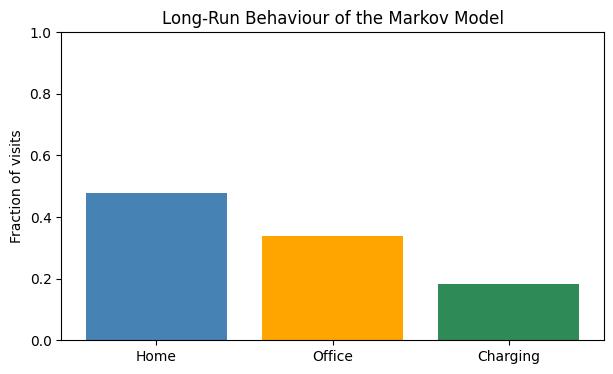

In [2]:
states = ['Home', 'Office', 'Charging']
transition_matrix = np.array([
    [0.60, 0.30, 0.10],  # from Home
    [0.25, 0.55, 0.20],  # from Office
    [0.50, 0.20, 0.30]   # from Charging
])

def simulate_markov_chain(start_state, steps):
    path = [start_state]
    current = start_state
    for _ in range(steps):
        current = np.random.choice(len(states), p=transition_matrix[current])
        path.append(current)
    return path

path = simulate_markov_chain(start_state=0, steps=200)
counts = np.bincount(path, minlength=len(states))
frequencies = counts / len(path)

print('First 20 simulated states:', [states[i] for i in path[:20]])
for state, frequency in zip(states, frequencies):
    print(f'{state:9}: {frequency:.3f}')

plt.figure(figsize=(7, 4))
plt.bar(states, frequencies, color=['steelblue', 'orange', 'seagreen'])
plt.ylim(0, 1)
plt.ylabel('Fraction of visits')
plt.title('Long-Run Behaviour of the Markov Model')
plt.show()

## 2. Reward-Based Decision-Making

The agent starts at state 0 and chooses **Left** or **Right**. State 3 is the goal and state 0 is a penalty state. The immediate reward determines the greedy choice.

In [3]:
actions = ['Left', 'Right']
# Reward for taking each action in each state. Rows = states 0..3; columns = Left, Right.
rewards = np.array([[-5, -1], [-2,  1], [ 1, 10], [0, 0]], dtype=float)

def greedy_reward_action(state, reward_table):
    return actions[np.argmax(reward_table[state])]

print('Initial reward table (state 0):', dict(zip(actions, rewards[0])))
print('Greedy choice at state 0:', greedy_reward_action(0, rewards))

changed_rewards = rewards.copy()
changed_rewards[0, 0] = 3  # make Left attractive at state 0
print('After changing Left reward to +3:', dict(zip(actions, changed_rewards[0])))
print('New greedy choice at state 0:', greedy_reward_action(0, changed_rewards))

Initial reward table (state 0): {'Left': -5.0, 'Right': -1.0}
Greedy choice at state 0: Right
After changing Left reward to +3: {'Left': 3.0, 'Right': -1.0}
New greedy choice at state 0: Left


## 3. Q-Learning

The environment is a 1-D corridor with states `0, 1, 2, 3, 4`. The agent begins at state 2. Reaching state 4 gives +10 (success), reaching state 0 gives -10, and every other move costs -1. States 0 and 4 are terminal.

Learned Q-table (Left, Right):
[[ 0.    0.  ]
 [-3.86  6.  ]
 [ 3.81  8.  ]
 [ 6.09 10.  ]
 [ 0.    0.  ]]
Learned policy: {0: 'Terminal', 1: 'Right', 2: 'Right', 3: 'Right', 4: 'Terminal'}


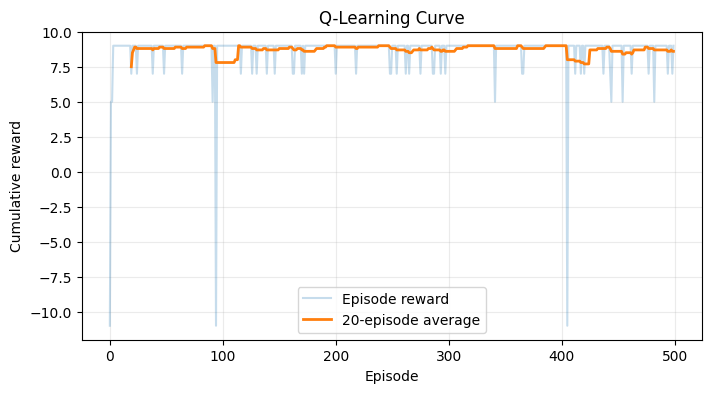

In [4]:
N_STATES, N_ACTIONS = 5, 2
LEFT, RIGHT = 0, 1

def step(state, action):
    next_state = max(0, state - 1) if action == LEFT else min(N_STATES - 1, state + 1)
    if next_state == 4:
        return next_state, 10, True
    if next_state == 0:
        return next_state, -10, True
    return next_state, -1, False

def train_q_learning(episodes=500, alpha=0.15, gamma=0.9, epsilon=0.1, seed=0):
    rng = np.random.default_rng(seed)
    q_table = np.zeros((N_STATES, N_ACTIONS))
    episode_rewards = []

    for _ in range(episodes):
        state, total_reward, done = 2, 0, False
        while not done:
            if rng.random() < epsilon:
                action = rng.integers(N_ACTIONS)
            else:
                action = int(np.argmax(q_table[state]))
            next_state, reward, done = step(state, action)
            target = reward if done else reward + gamma * np.max(q_table[next_state])
            q_table[state, action] += alpha * (target - q_table[state, action])
            state, total_reward = next_state, total_reward + reward
        episode_rewards.append(total_reward)
    return q_table, np.array(episode_rewards)

q_table, learning_rewards = train_q_learning()
policy = ['Terminal' if s in (0, 4) else actions[np.argmax(q_table[s])] for s in range(N_STATES)]

print('Learned Q-table (Left, Right):')
print(np.round(q_table, 2))
print('Learned policy:', dict(enumerate(policy)))

moving_average = np.convolve(learning_rewards, np.ones(20) / 20, mode='valid')
plt.figure(figsize=(8, 4))
plt.plot(learning_rewards, alpha=0.25, label='Episode reward')
plt.plot(range(19, len(learning_rewards)), moving_average, linewidth=2, label='20-episode average')
plt.xlabel('Episode')
plt.ylabel('Cumulative reward')
plt.title('Q-Learning Curve')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 4 & 5. Exploration vs Exploitation and Discount Factor

Different values of epsilon control random exploration. Gamma controls how strongly the agent values future rewards.

Setting          Train reward  Eval reward    Avg steps   Success rate
--------------------------------------------------------------------------
epsilon=0.01             9.00         9.00         2.00           100%
epsilon=0.10             8.84         9.00         2.00           100%
epsilon=0.40             6.08         9.00         2.00           100%
gamma=0.20               8.84         9.00         2.00           100%
gamma=0.99               8.84         9.00         2.00           100%


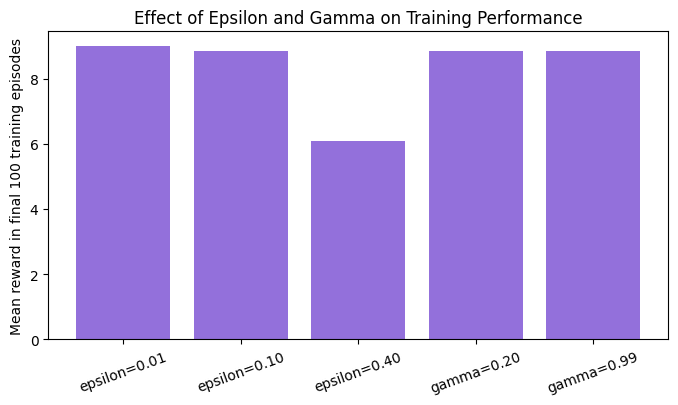

In [5]:
def evaluate_policy(q_table, trials=100):
    total_rewards, steps_list, successes = [], [], 0
    for _ in range(trials):
        state, total_reward, steps, done = 2, 0, 0, False
        while not done and steps < 20:
            action = int(np.argmax(q_table[state]))
            state, reward, done = step(state, action)
            total_reward += reward
            steps += 1
        successes += state == 4
        total_rewards.append(total_reward)
        steps_list.append(steps)
    return np.mean(total_rewards), np.mean(steps_list), 100 * successes / trials

settings = [('epsilon=0.01', 0.01, 0.9), ('epsilon=0.10', 0.10, 0.9),
            ('epsilon=0.40', 0.40, 0.9), ('gamma=0.20', 0.10, 0.2),
            ('gamma=0.99', 0.10, 0.99)]
results = []

for name, epsilon, gamma in settings:
    q, rewards_run = train_q_learning(epsilon=epsilon, gamma=gamma, seed=10)
    mean_reward, mean_steps, success_rate = evaluate_policy(q)
    final_training_reward = np.mean(rewards_run[-100:])
    results.append((name, final_training_reward, mean_reward, mean_steps, success_rate))

print(f"{'Setting':<15} {'Train reward':>13} {'Eval reward':>12} {'Avg steps':>12} {'Success rate':>14}")
print('-' * 74)
for name, train_reward, avg_reward, avg_steps, rate in results:
    print(f'{name:<15} {train_reward:>13.2f} {avg_reward:>12.2f} {avg_steps:>12.2f} {rate:>13.0f}%')

labels = [row[0] for row in results]
plt.figure(figsize=(8, 4))
plt.bar(labels, [row[1] for row in results], color='mediumpurple')
plt.ylabel('Mean reward in final 100 training episodes')
plt.title('Effect of Epsilon and Gamma on Training Performance')
plt.xticks(rotation=20)
plt.show()

## Observation

- The state frequencies settle toward a stable distribution as the Markov simulation becomes longer.
- Changing immediate rewards can change the action selected by a greedy agent.
- Q-learning learns to move right toward the +10 terminal state.
- Very low epsilon may reduce exploration; a high epsilon keeps the agent exploring but can lower training rewards.
- A larger discount factor gives more importance to future rewards.
- Policy evaluation reports average reward, steps, and success rate for each setting.